In [ ]:
!pip install rasterio -qq

In [10]:
from google.colab import drive
import ee
import geemap
import time
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import geopandas as gpd
import pandas as pd
from shapely.geometry import Polygon, MultiPolygon

# mount google drive
drive.mount('/content/drive')

# autenticate for gee login
ee.Authenticate()

# project id
cloud_project = 'hello-514508' # replace with your own project id
ee.Initialize(project=cloud_project)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Define the Bounding Box (AOI) for the glacier in Western Nepal
aoi_coords = [
    [81.756821, 30.184416],
    [81.791840, 30.184416],
    [81.791840, 30.255022],
    [81.756821, 30.255022],
    [81.756821, 30.184416]
]
aoi = ee.Geometry.Polygon([aoi_coords])

# Load GLIMS glacier outlines for reference
glims = ee.FeatureCollection('GLIMS/current').filterBounds(aoi)

# ============================================================================
# 2. LOAD LANDSAT 8 & 9 LEVEL-2 DATA, MASK CLOUDS & COMPUTE LST (°C)
# ============================================================================
def prep_landsat_lst(img):
    qa = img.select('QA_PIXEL')
    # Mask clouds (Bit 3) and cloud shadows (Bit 4)
    mask = qa.bitwiseAnd(1 << 3).eq(0).And(qa.bitwiseAnd(1 << 4).eq(0))

    # Convert Band 10 Surface Temperature: Kelvin = DN * 0.00341802 + 149.0 -> Celsius
    lst_celsius = (
        img.select('ST_B10')
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename('LST')
    )
    return lst_celsius.updateMask(mask).copyProperties(img, ['system:time_start'])

start_date = '2014-01-01'
end_date = '2024-12-31'

l8 = ee.ImageCollection('LANDSAT/LC08/C02/T1_L2').filterBounds(aoi).filterDate(start_date, end_date)
l9 = ee.ImageCollection('LANDSAT/LC09/C02/T1_L2').filterBounds(aoi).filterDate(start_date, end_date)

lst_collection = (
    l8.merge(l9)
    .filter(ee.Filter.lt('CLOUD_COVER', 60))
    .map(prep_landsat_lst)
)

# ============================================================================
# 3. COMPUTE SEASONAL MEAN COMPOSITES & INTERACTIVE MAP
# ============================================================================
winter_lst = lst_collection.filter(ee.Filter.calendarRange(12, 2, 'month')).mean().clip(aoi)
spring_lst = lst_collection.filter(ee.Filter.calendarRange(3, 5, 'month')).mean().clip(aoi)
summer_lst = lst_collection.filter(ee.Filter.calendarRange(6, 8, 'month')).mean().clip(aoi)
autumn_lst = lst_collection.filter(ee.Filter.calendarRange(9, 11, 'month')).mean().clip(aoi)

lst_vis = {
    'min': -25,
    'max': 15,
    'palette': ['040274', '2c7bb6', '00a6ca', 'ffffbf', 'fdae61', 'd7191c']
}

# Create interactive geemap Map to inspect layers and optionally draw a centerline
m = geemap.Map()
m.centerObject(aoi, 13)
m.addLayer(winter_lst, lst_vis, 'Mean LST - Winter (DJF)')
m.addLayer(spring_lst, lst_vis, 'Mean LST - Spring (MAM)')
m.addLayer(summer_lst, lst_vis, 'Mean LST - Summer (JJA)')
m.addLayer(autumn_lst, lst_vis, 'Mean LST - Autumn (SON)')
m.addLayer(glims, {'color': 'cyan'}, 'GLIMS Glacier Outlines')
m  # Display the interactive map in Jupyter/Colab

Map(center=[30.219715940250264, 81.7743305000095], controls=(WidgetControl(options=['position', 'transparent_b…

Using user-drawn centerline from the interactive map.


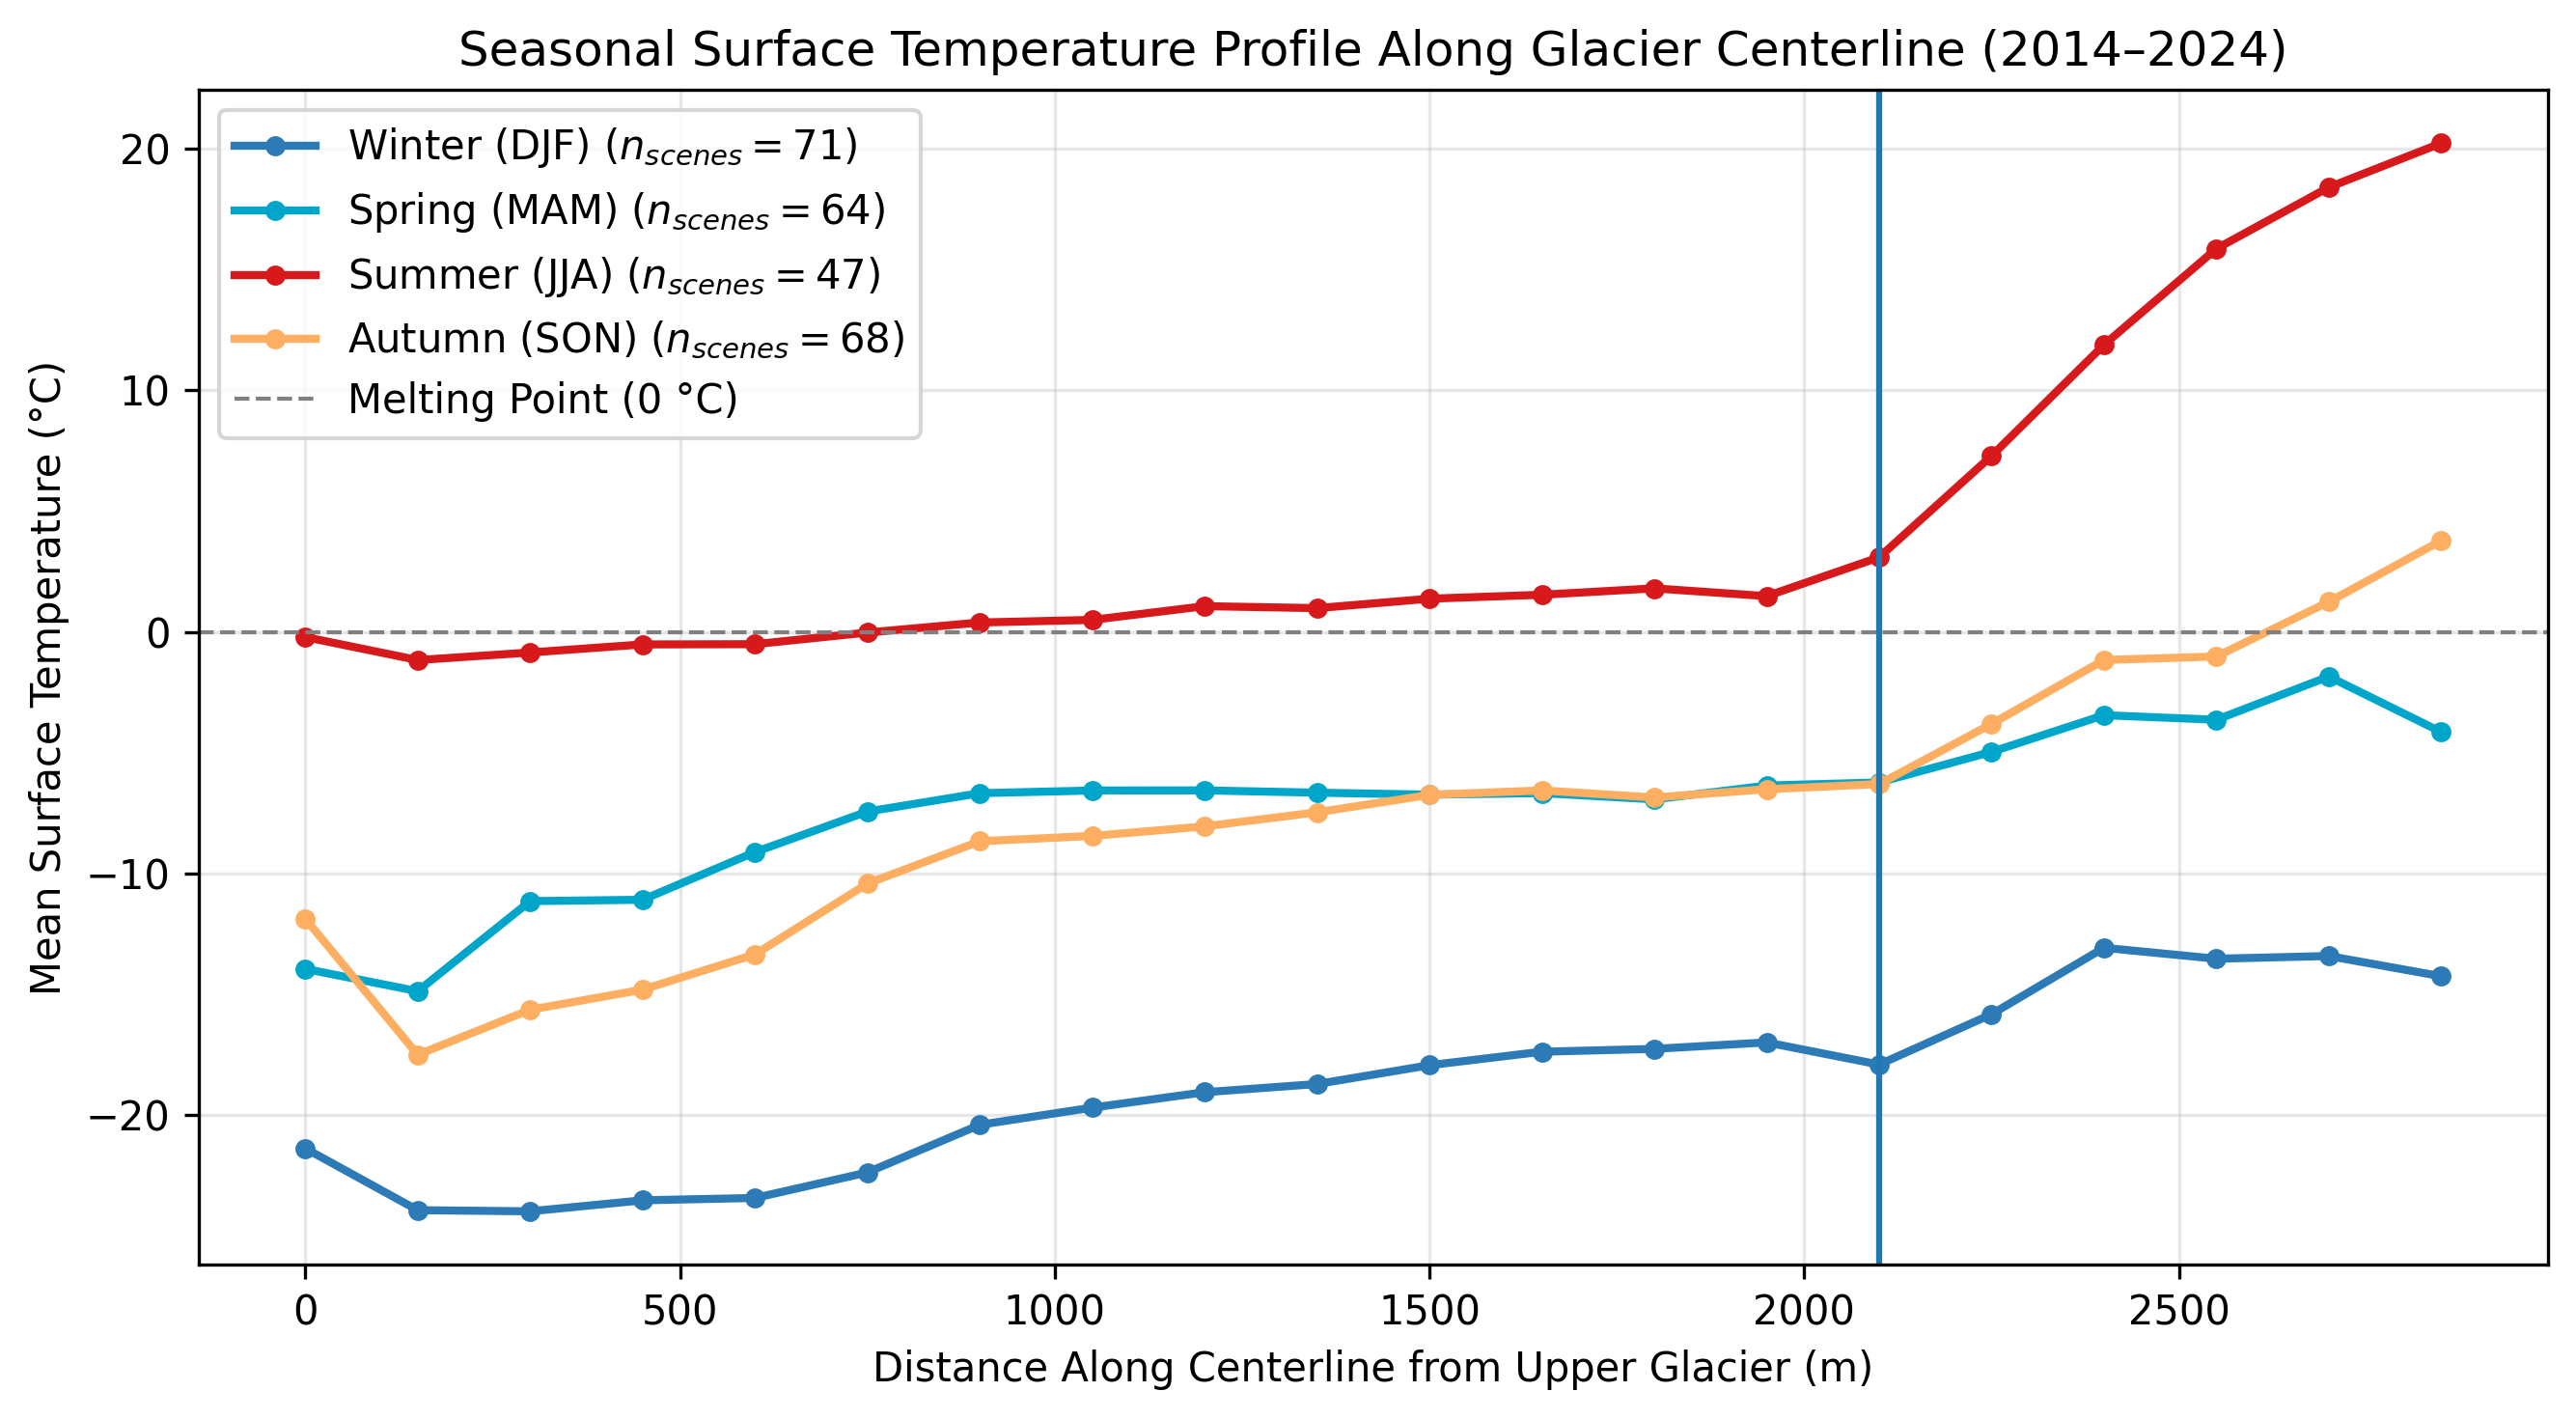

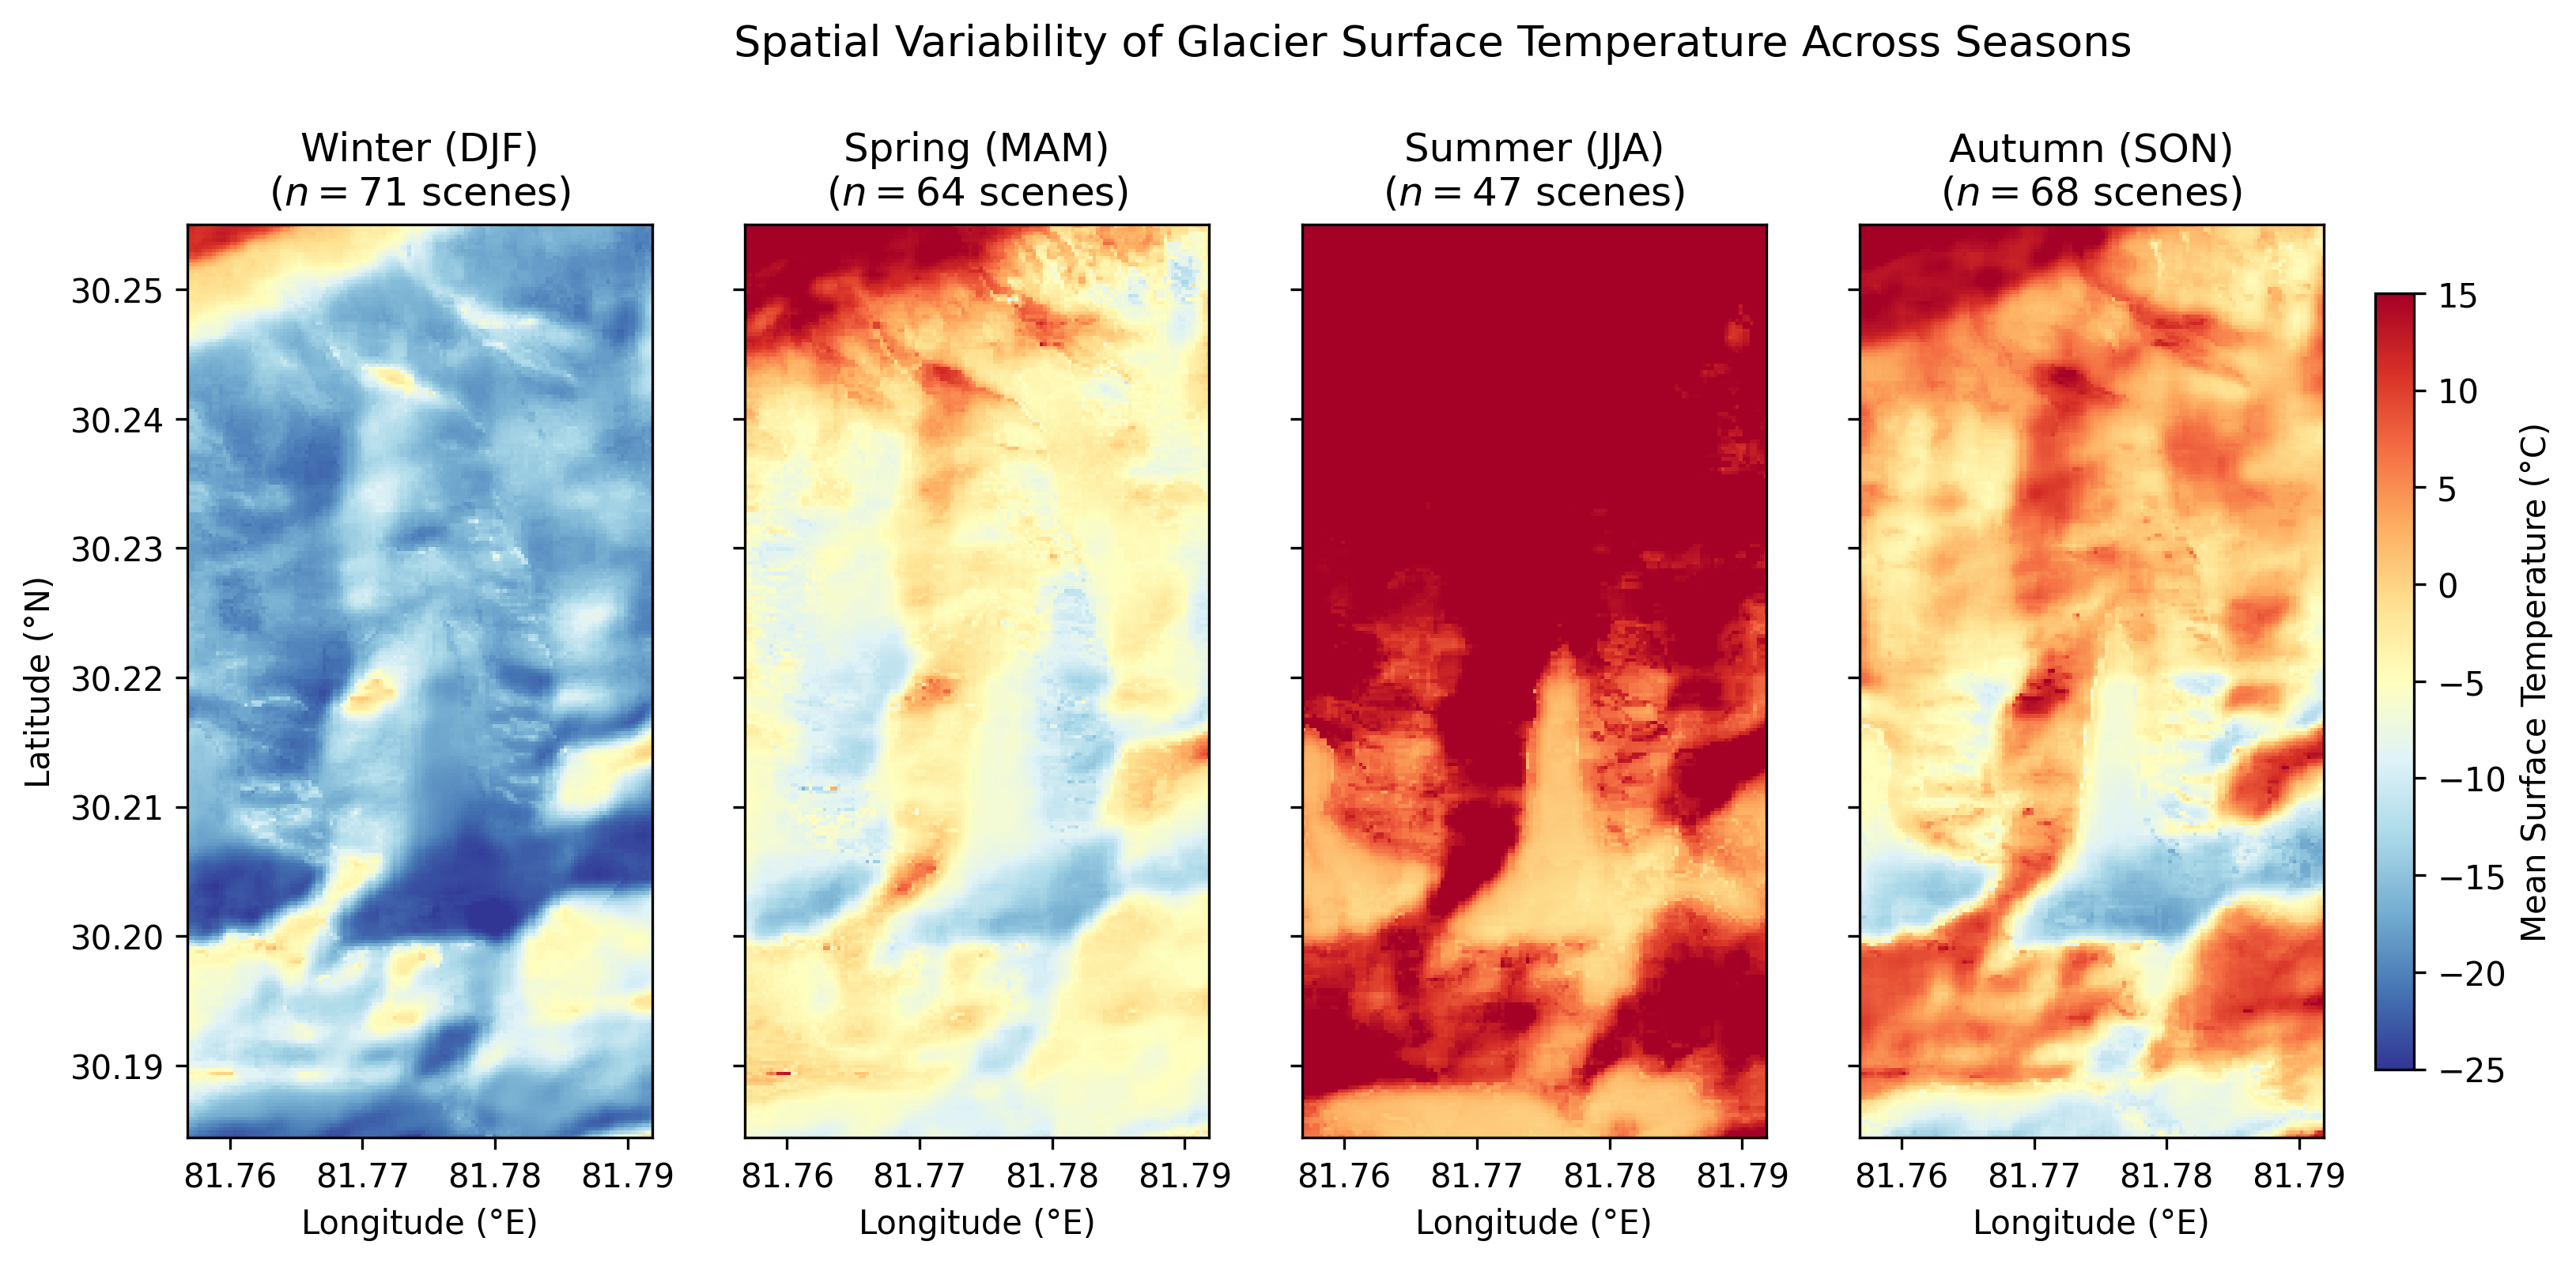

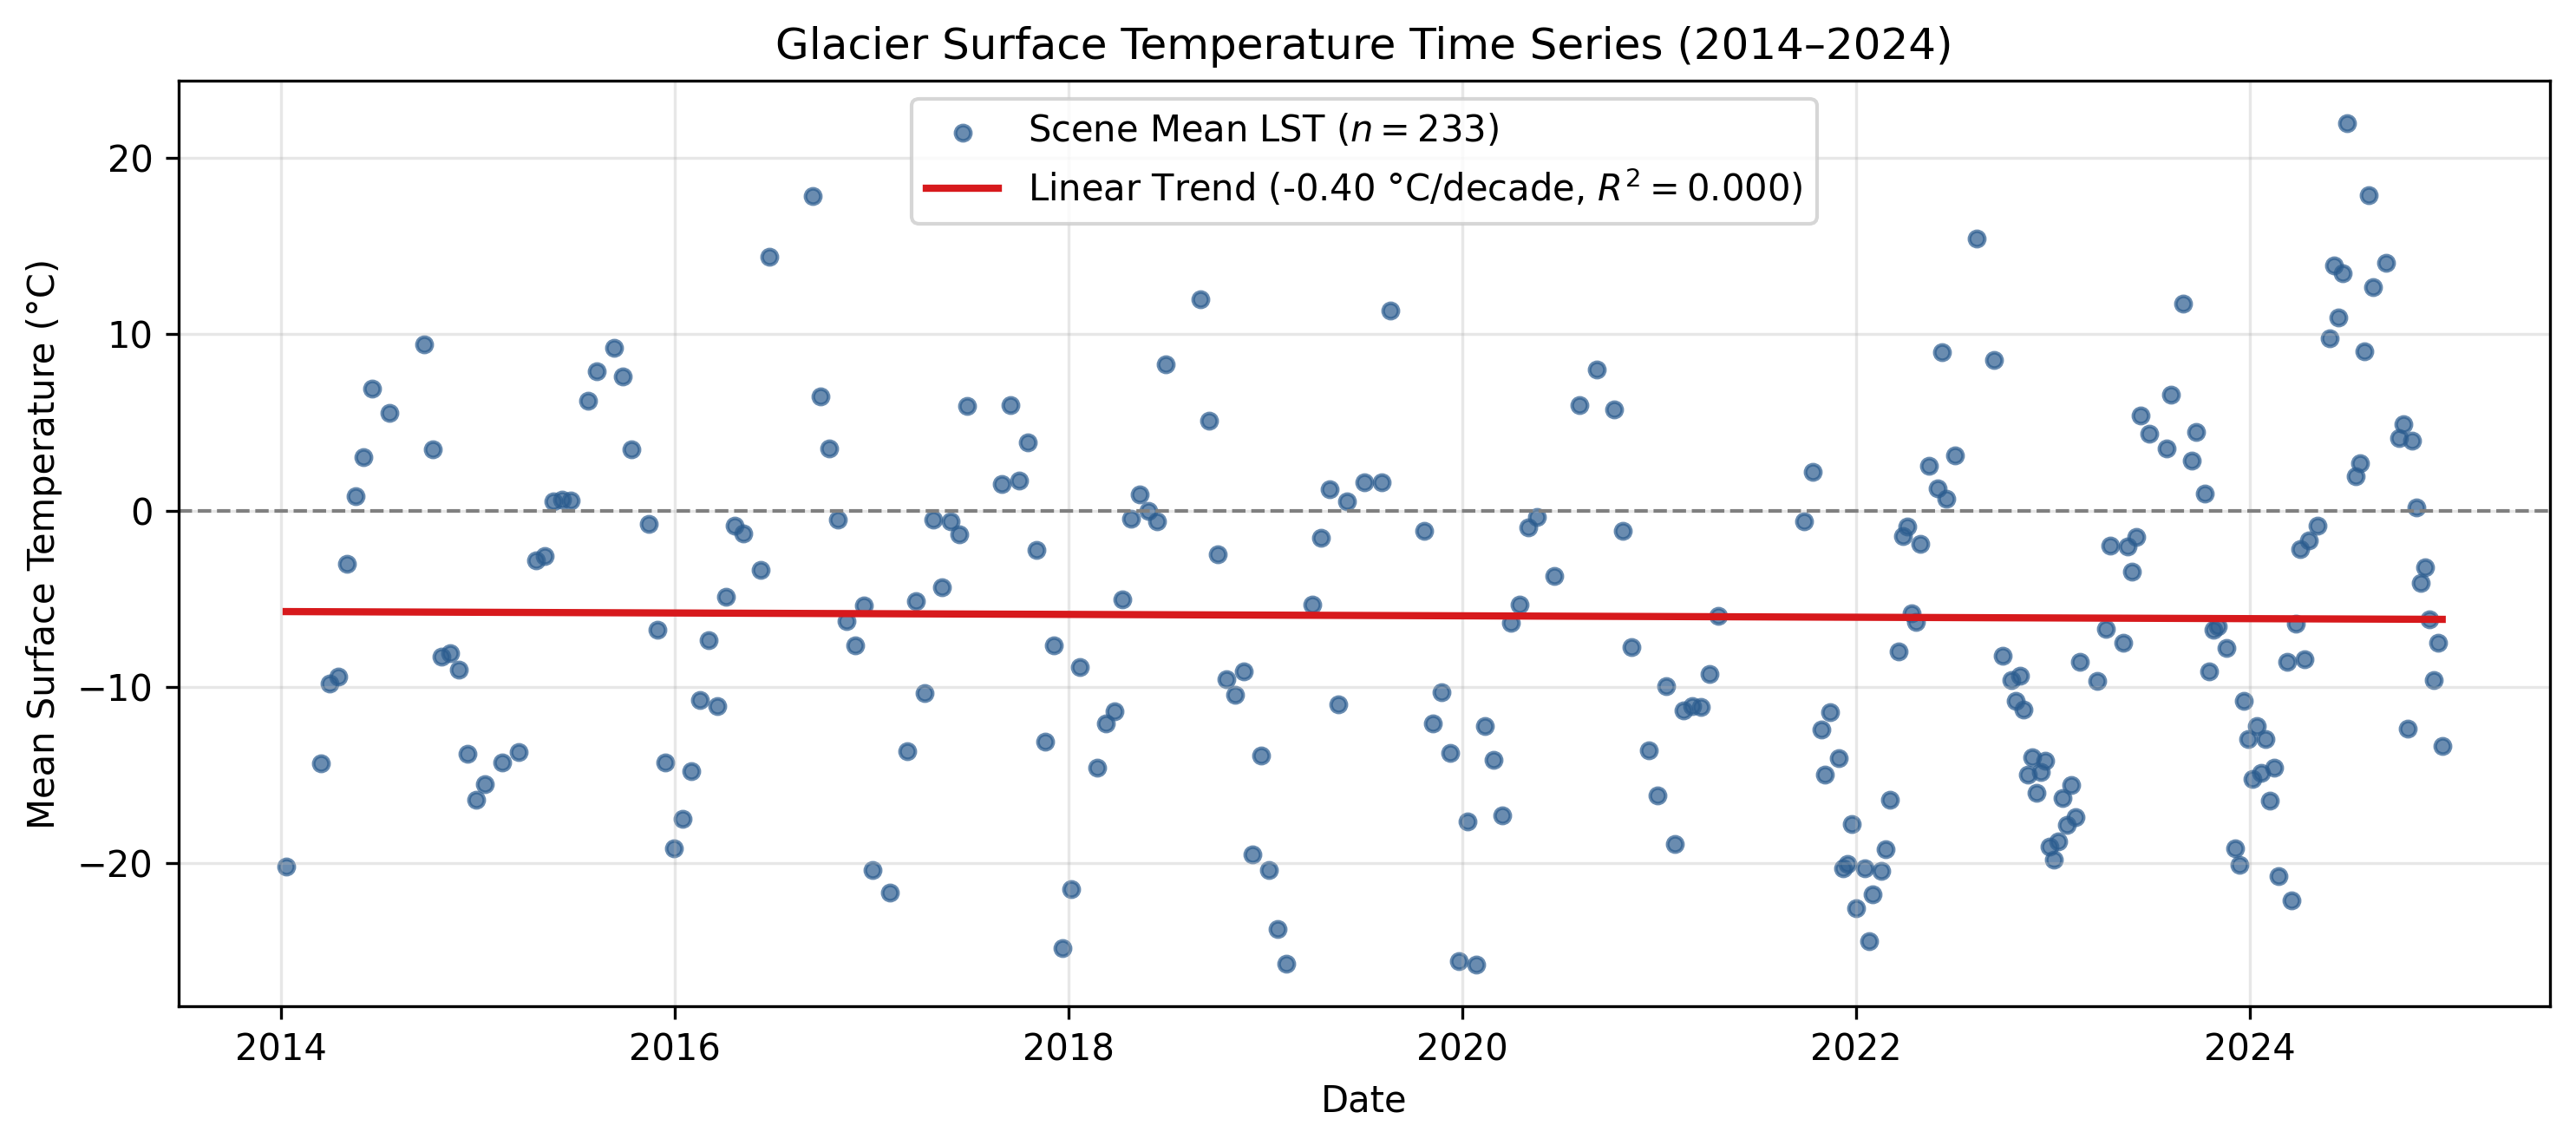

In [15]:
# ============================================================================
# 4. DEFINE CENTERLINE & EXTRACT SEASONAL TEMPERATURE PROFILE (DELIVERABLE 2a)
# ============================================================================
# If you drew a line on the geemap map above, use m.user_roi; otherwise use the default centerline
if m.user_roi is not None and m.user_roi.type().getInfo() == 'LineString':
    centerline = ee.Geometry.LineString(m.user_roi.coordinates(), 'EPSG:4326', True)
    print("Using user-drawn centerline from the interactive map.")
else:
    centerline = ee.Geometry.LineString([
        [81.773, 30.245],
        [81.776, 30.220],
        [81.775, 30.195]
    ])
    print("Using default glacier centerline.")

seasonal_stack = ee.Image.cat([
    winter_lst.rename('Winter_DJF'),
    spring_lst.rename('Spring_MAM'),
    summer_lst.rename('Summer_JJA'),
    autumn_lst.rename('Autumn_SON')
])

# Count the number of satellite scenes (sample size n) in each season
season_counts = ee.Dictionary({
    'Winter_DJF': lst_collection.filter(ee.Filter.calendarRange(12, 2, 'month')).size(),
    'Spring_MAM': lst_collection.filter(ee.Filter.calendarRange(3, 5, 'month')).size(),
    'Summer_JJA': lst_collection.filter(ee.Filter.calendarRange(6, 8, 'month')).size(),
    'Autumn_SON': lst_collection.filter(ee.Filter.calendarRange(9, 11, 'month')).size()
}).getInfo()

# Generate sample points every 150 meters along the centerline (with 1m maxError)
step_meters = 150
line_length = centerline.length(1).getInfo()
cut_distances = ee.List.sequence(step_meters, line_length, step_meters)
segments = centerline.cutLines(cut_distances, 1).geometries()

def make_sample_point(i):
    i = ee.Number(i)
    seg = ee.Geometry(segments.get(i))
    pt = ee.Geometry.Point(seg.coordinates().get(0))
    return ee.Feature(pt, {'distance_m': i.multiply(step_meters)})

sample_points = ee.FeatureCollection(
    ee.List.sequence(0, segments.length().subtract(1)).map(make_sample_point)
)

profile_fc = seasonal_stack.reduceRegions(
    collection=sample_points,
    reducer=ee.Reducer.mean(),
    scale=30
)

# Convert extracted centerline features to a Pandas DataFrame
profile_features = profile_fc.getInfo()['features']
profile_rows = [f['properties'] for f in profile_features]
df_profile = pd.DataFrame(profile_rows).sort_values('distance_m')

# Plot Centerline Seasonal Temperature Profile with seasonal sample sizes (n)
plt.figure(figsize=(9, 5), dpi=300)
season_cols = [
    ('Winter_DJF', 'Winter (DJF)', '#2c7bb6'),
    ('Spring_MAM', 'Spring (MAM)', '#00a6ca'),
    ('Summer_JJA', 'Summer (JJA)', '#d7191c'),
    ('Autumn_SON', 'Autumn (SON)', '#fdae61')
]

for col, label, color in season_cols:
    if col in df_profile.columns:
        n_scenes = season_counts.get(col, 0)
        n_pts = df_profile[col].dropna().count()
        # Displays number of scenes (n) and centerline points; adjust label string if only one is needed
        plt.plot(
            df_profile['distance_m'],
            df_profile[col],
            marker='o',
            markersize=4,
            linewidth=2,
            label=f'{label} ($n_{{scenes}}={n_scenes}$)',
            color=color
        )

plt.axhline(0, color='gray', linestyle='--', linewidth=1, label='Melting Point (0 °C)')
plt.title('Seasonal Surface Temperature Profile Along Glacier Centerline (2014–2024)')
plt.xlabel('Distance Along Centerline from Upper Glacier (m)')
plt.ylabel('Mean Surface Temperature (°C)')
plt.legend()
plt.axvline(2100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('task3_centerline_profile.png')
plt.show()

# ============================================================================
# 5. SPATIAL VARIABILITY FIGURE ACROSS SEASONS (DELIVERABLE 3)
# ============================================================================
# Reproject to 30m grid in EPSG:4326 and download array via sampleRectangle
stack_grid = seasonal_stack.unmask(-9999).reproject(crs='EPSG:4326', scale=30)
rect_dict = stack_grid.sampleRectangle(region=aoi, defaultValue=-9999).getInfo()['properties']

fig, axes = plt.subplots(1, 4, figsize=(14, 5), dpi=300, sharey=True)
extent = [81.756821, 81.791840, 30.184416, 30.255022]

for ax, (col, label, _) in zip(axes, season_cols):
    arr = np.array(rect_dict[col], dtype=float)
    arr[arr == -9999] = np.nan
    im = ax.imshow(arr, cmap='RdYlBu_r', vmin=-25, vmax=15, extent=extent, aspect='auto')
    ax.set_title(f"{label}\n($n={season_counts.get(col, 0)}$ scenes)")
    ax.set_xlabel('Longitude (°E)')

axes[0].set_ylabel('Latitude (°N)')
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, pad=0.02)
cbar.set_label('Mean Surface Temperature (°C)')
plt.suptitle('Spatial Variability of Glacier Surface Temperature Across Seasons', y=1.05, fontsize=13)
plt.savefig('task3_seasonal_spatial_variability.png', bbox_inches='tight')
plt.show()

# ============================================================================
# 6. MULTI-YEAR SURFACE TEMPERATURE TIME SERIES WITH R^2 (DELIVERABLE 2b)
# ============================================================================
study_region = (
    glims.geometry(1).intersection(aoi, 1)
    if glims.size().getInfo() > 0
    else aoi
)

def extract_ts(img):
    mean_dict = img.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=study_region,
        scale=30,
        maxPixels=1e8
    )
    return ee.Feature(None, {
        'date': img.date().format('YYYY-MM-dd'),
        'LST': mean_dict.get('LST')
    })

ts_features = lst_collection.map(extract_ts).filter(ee.Filter.notNull(['LST'])).getInfo()['features']
df_ts = pd.DataFrame([f['properties'] for f in ts_features])
df_ts['date'] = pd.to_datetime(df_ts['date'])
df_ts = df_ts.sort_values('date')

# Fit linear trendline and compute R^2
x_num = mdates.date2num(df_ts['date'])
y_val = df_ts['LST'].values
slope, intercept = np.polyfit(x_num, y_val, 1)
y_pred = slope * x_num + intercept
warming_per_decade = slope * 365.25 * 10

# Calculate R^2 (Coefficient of Determination)
ss_res = np.sum((y_val - y_pred) ** 2)
ss_tot = np.sum((y_val - np.mean(y_val)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

plt.figure(figsize=(10, 4.5), dpi=300)
plt.scatter(
    df_ts['date'],
    y_val,
    s=18,
    alpha=0.7,
    color='#2b5c8f',
    label=f'Scene Mean LST ($n = {len(df_ts)}$)'
)
plt.plot(
    df_ts['date'],
    y_pred,
    color='#d7191c',
    linewidth=2,
    label=f'Linear Trend ({warming_per_decade:+.2f} °C/decade, $R^2 = {r_squared:.3f}$)'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Glacier Surface Temperature Time Series (2014–2024)')
plt.xlabel('Date')
plt.ylabel('Mean Surface Temperature (°C)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('task3_lst_timeseries.png')
plt.show()